# Statistik med Python – de viktigaste koncepten

Den här notebooken går igenom kursens statistiska begrepp med korta, körbara exempel:

1. Population och stickprov
2. Variabeltyper
3. Deskriptiv statistik
4. Analys av fördelningar
5. Datakvalitet, felkällor och bias
6. Punktskattning och konfidensintervall
7. Hypotesprövning och p-värden
8. Test för skillnad mellan två andelar
9. Typ I- och typ II-fel
10. Sambandsanalys: korstabeller och chi-två-test
11. Korrelationsanalys
12. Enkel linjär regression
13. Samma analyser i R
14. Kritisk värdering av slutsatser

All data är **simulerad**. Därför vet vi det "sanna" svaret och kan jämföra det med det statistiken säger.
Kör cellerna uppifrån och ned (eller **Restart & Run All**).

Varje avsnitt slutar med en **Prova själv**-fråga. Koden förklaras i `statistik_kodguide.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # ett fixerat random seed ger samma "slump" varje gång

## 1. Population och stickprov

- **Population:** alla individer vi vill uttala oss om.
- **Stickprov:** den delmängd vi faktiskt undersöker.
- **Parameter:** ett mått på populationen (oftast okänt).  
**Statistika/skattning:** samma mått beräknat på stickprovet.

| Mått | Population (parameter) | Stickprov (skattning) |
|---|---|---|
| Medelvärde | μ | x̄ |
| Andel | p | p̂ |
| Standardavvikelse | σ | s |

Vi skapar en påhittad population med 10 000 personer.

In [2]:
N = 10_000
population = pd.DataFrame({
    "height": rng.normal(172, 9, N).round(1),                       # cm
    "num_children": rng.poisson(1.5, N),
    "education": rng.choice(["Grundskola", "Gymnasium", "Högskola"], N, p=[0.2, 0.45, 0.35]),
    "income": rng.lognormal(np.log(32), 0.4, N).round(1),          # tkr per månad
})
population.head()

,height,num_children,education,income
0,174.7,1,Gymnasium,26.8
1,162.6,1,Högskola,38.8
2,178.8,1,Gymnasium,29.7
3,180.5,1,Grundskola,43.0
4,154.4,1,Gymnasium,72.0


I verkligheten känner vi nästan aldrig till populationens parametrar. Här gör vi det:

In [3]:
mu = population["height"].mean()
p = (population["education"] == "Högskola").mean()
print(f"Populationsmedelvärde μ = {mu:.2f} cm")
print(f"Populationsandel högskola p = {p:.3f}")

Populationsmedelvärde μ = 171.91 cm
Populationsandel högskola p = 0.355


### Obundet slumpmässigt urval (OSU)

I ett OSU har **alla individer samma chans** att komma med i stickprovet.

In [4]:
sample = population.sample(n=100, random_state=1)

x_bar = sample["height"].mean()
p_hat = (sample["education"] == "Högskola").mean()
print(f"Stickprovsmedelvärde x̄ = {x_bar:.2f} cm   (sant μ = {mu:.2f})")
print(f"Stickprovsandel p̂ = {p_hat:.3f}   (sant p = {p:.3f})")

Stickprovsmedelvärde x̄ = 170.58 cm   (sant μ = 171.91)
Stickprovsandel p̂ = 0.280   (sant p = 0.355)


Skattningen hamnar nära, men inte exakt på, det sanna värdet. Skillnaden kallas **urvalsfel**.
Det är inget misstag, utan en följd av att vi bara undersöker en del av populationen.

Lägg märke till att andelen träffar sämre än medelvärdet: p̂ = 0,28 mot p = 0,355. Med n = 100 är
osäkerheten i en andel ungefär ±9 procentenheter (se avsnitt 6), så en sådan avvikelse är inte ovanlig.

### Stickprovsstorlekens betydelse

Vi drar 500 olika stickprov av storlek *n* och tittar på hur mycket medelvärdena varierar.

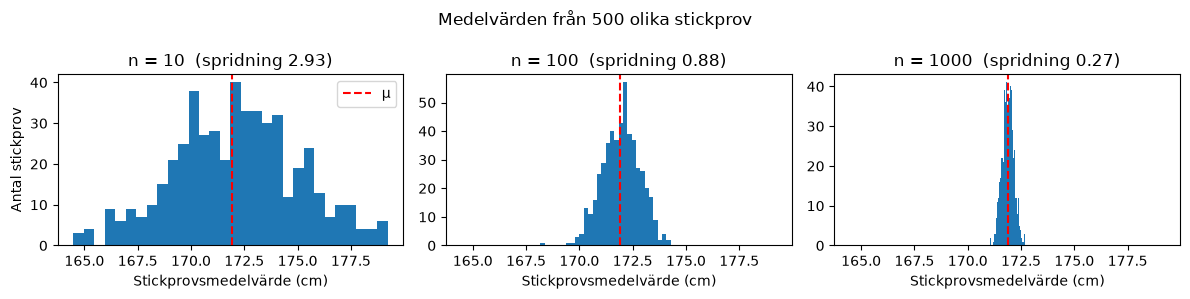

In [5]:
heights = population["height"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True)
for ax, sample_size in zip(axes, [10, 100, 1000]):
    means = [rng.choice(heights, sample_size, replace=False).mean() for _ in range(500)]
    ax.hist(means, bins=30)
    ax.axvline(mu, color="red", linestyle="--", label="μ")
    ax.set_title(f"n = {sample_size}  (spridning {np.std(means):.2f})")
    ax.set_xlabel("Stickprovsmedelvärde (cm)")
axes[0].set_ylabel("Antal stickprov")
axes[0].legend()
fig.suptitle("Medelvärden från 500 olika stickprov")
plt.tight_layout()
plt.show()

**Större stickprov ger mindre urvalsfel.** Spridningen minskar ungefär som $1/\sqrt{n}$:
ett 100 gånger större stickprov ger ungefär 10 gånger mindre spridning.

### Centrala gränsvärdessatsen

Längd är redan normalfördelad, så det är inte överraskande att medelvärdena också blir det.
Men samma sak händer för **sned** data. Inkomsterna i populationen är högersneda. Vi drar 500 stickprov
och tittar på hur *medelinkomsterna* fördelar sig:

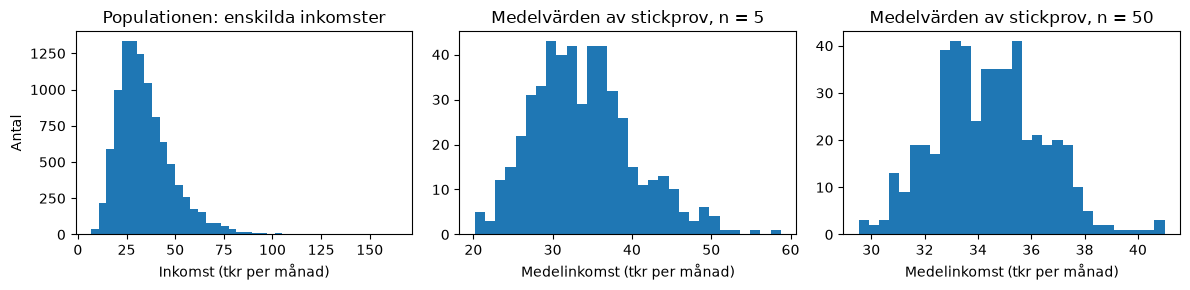

In [6]:
incomes = population["income"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(incomes, bins=40)
axes[0].set_title("Populationen: enskilda inkomster")
axes[0].set_ylabel("Antal")
for ax, sample_size in zip(axes[1:], [5, 50]):
    means = [rng.choice(incomes, sample_size, replace=False).mean() for _ in range(500)]
    ax.hist(means, bins=30)
    ax.set_title(f"Medelvärden av stickprov, n = {sample_size}")
    ax.set_xlabel("Medelinkomst (tkr per månad)")
axes[0].set_xlabel("Inkomst (tkr per månad)")
plt.tight_layout()
plt.show()

**Centrala gränsvärdessatsen (CGS):** medelvärdet av ett tillräckligt stort slumpmässigt stickprov är ungefär
normalfördelat, **oavsett hur populationen är fördelad**. Med n = 5 syns snedheten fortfarande, med n = 50 är
klockformen tydlig. En vanlig tumregel är n ≥ 30, men mycket sned data kräver mer.

Det är därför metoderna i avsnitt 6 och 7 (konfidensintervall och t-test) fungerar även när datan inte är normalfördelad.

> **Prova själv:** Ändra `n=100` till `n=400` i cellen där `sample` dras och kör om den. Hamnar x̄ och p̂ närmare de sanna värdena? Byt sedan `random_state` några gånger: hur mycket varierar skattningarna? Ändra tillbaka efteråt, eftersom resten av notebooken bygger på stickprovet.

## 2. Variabeltyper

| Typ | Beskrivning | Exempel i datan |
|---|---|---|
| **Kvalitativ** (kategorisk) | Kategorier, inte tal | `education` |
| **Kvantitativ, diskret** | Räknas i hela steg | `num_children` |
| **Kvantitativ, kontinuerlig** | Kan anta vilket värde som helst i ett intervall | `height`, `income` |

Variabler delas också in efter **skalnivå**, som avgör vilka beräkningar som är meningsfulla:

| Skalnivå | Kännetecken | Exempel | Lämpligt lägesmått |
|---|---|---|---|
| **Nominalskala** | Kategorier utan ordning | kanal (App/Webb/Butik) | Typvärde |
| **Ordinalskala** | Kategorier med naturlig ordning, men avstånden mellan dem är inte bestämda | `education` | Typvärde, median |
| **Intervallskala** | Lika stora steg, men ingen äkta nollpunkt | temperatur i °C | Medelvärde, median |
| **Kvotskala** | Lika stora steg och äkta nollpunkt, så "dubbelt så mycket" är meningsfullt | `height`, `income`, `num_children` | Medelvärde, median |

Variabeltypen avgör vilka tabeller, diagram och metoder som passar.

In [7]:
sample.dtypes

height          float64
num_children      int64
education           str
income          float64
dtype: object

`dtypes` visar hur pandas **lagrar** värdena, inte variabeltypen i statistisk mening. Text visas som `str`
(i pandas före version 3 som `object`), och pandas vet inte att `education` har en naturlig ordning.
Det måste vi själva hålla reda på.

> **Prova själv:** Vilken variabeltyp och skalnivå har ett postnummer? Det består av siffror, men är det meningsfullt att räkna ut ett medelvärde?

## 3. Deskriptiv statistik

Deskriptiv statistik **beskriver** datan vi har, utan att dra slutsatser om populationen.

### Frekvenstabell och stapeldiagram (kvalitativa och diskreta variabler)

In [8]:
order = ["Grundskola", "Gymnasium", "Högskola"]   # ordinalskala: visa kategorierna i naturlig ordning
frequency = sample["education"].value_counts().reindex(order)
pd.DataFrame({"frequency": frequency, "relative frequency": (frequency / frequency.sum()).round(2)})

,frequency,relative frequency
education,,
Grundskola,21,0.21
Gymnasium,51,0.51
Högskola,28,0.28


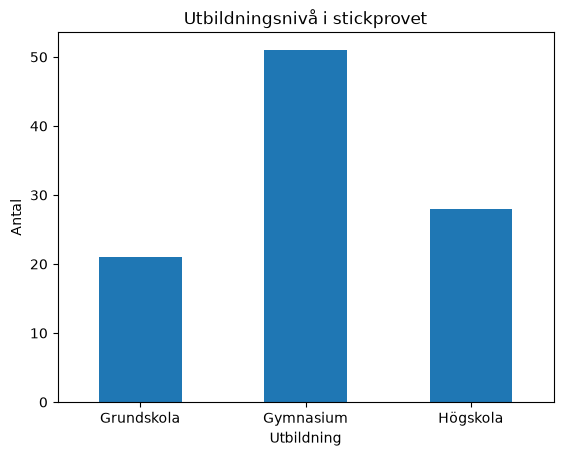

In [9]:
frequency.plot(kind="bar", rot=0, title="Utbildningsnivå i stickprovet")
plt.xlabel("Utbildning")
plt.ylabel("Antal")
plt.show()

### Histogram och klassindelning (kontinuerliga variabler)

En kontinuerlig variabel delas in i **klasser** (intervall). Antalet klasser påverkar bilden:
för få klasser döljer formen, för många ger brus.

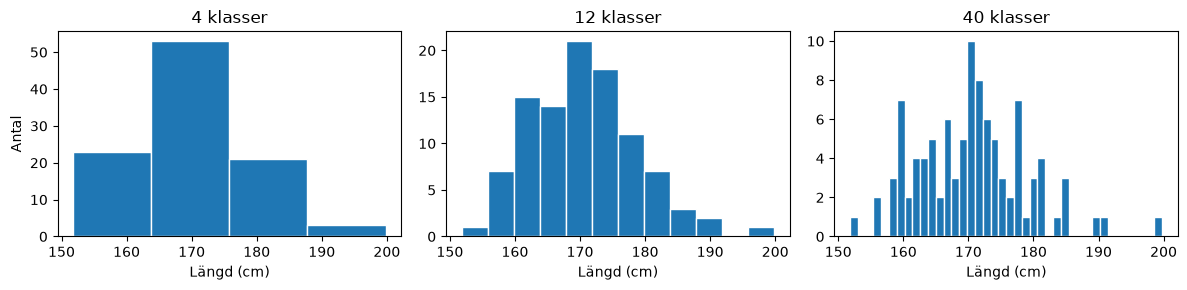

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, num_bins in zip(axes, [4, 12, 40]):
    ax.hist(sample["height"], bins=num_bins, edgecolor="white")
    ax.set_title(f"{num_bins} klasser")
    ax.set_xlabel("Längd (cm)")
axes[0].set_ylabel("Antal")
plt.tight_layout()
plt.show()

Klassindelningen som en frekvenstabell. Klassen `(160, 170]` innehåller värden större än 160 till och med 170.
Med `right=False` i `pd.cut` blir klasserna i stället `[160, 170)`, alltså från och med 160 upp till (men inte med) 170,
vilket är det skrivsätt många läroböcker använder.

In [11]:
classes = pd.cut(sample["height"], bins=range(140, 211, 10))
classes.value_counts().sort_index()

height
(140, 150]     0
(150, 160]    10
(160, 170]    36
(170, 180]    41
(180, 190]    11
(190, 200]     2
(200, 210]     0
Name: count, dtype: int64

### Lägesmått och spridningsmått

- **Lägesmått** beskriver var värdena ligger: **medelvärde**, **median** (det mittersta värdet) och **typvärde** (det vanligaste värdet).
- **Spridningsmått** beskriver hur utspridda de är: **standardavvikelse**, **variationsbredd** (största − minsta) och **kvartilavstånd** (Q3 − Q1).

**Kvartilerna** delar de sorterade värdena i fyra lika stora delar: 25 % av värdena ligger under Q1,
50 % under medianen och 75 % under Q3.

In [12]:
height = sample["height"]
q1, q3 = height.quantile([0.25, 0.75])

print(f"Medelvärde:        {height.mean():.1f} cm")
print(f"Median:            {height.median():.1f} cm")
print(f"Standardavvikelse: {height.std():.1f} cm   (pandas delar med n - 1)")
print(f"Min / max:         {height.min()} / {height.max()} cm")
print(f"Variationsbredd:   {height.max() - height.min():.1f} cm")
print(f"Kvartiler Q1 / Q3: {q1:.1f} / {q3:.1f} cm")
print(f"Kvartilavstånd:    {q3 - q1:.1f} cm")
print(f"Typvärde för antal barn: {sample['num_children'].mode()[0]}")

Medelvärde:        170.6 cm
Median:            170.3 cm
Standardavvikelse: 8.3 cm   (pandas delar med n - 1)
Min / max:         151.8 / 199.8 cm
Variationsbredd:   48.0 cm
Kvartiler Q1 / Q3: 164.6 / 175.3 cm
Kvartilavstånd:    10.7 cm
Typvärde för antal barn: 1


`describe()` ger en snabb översikt:

In [13]:
sample[["height", "num_children", "income"]].describe().round(1)

,height,num_children,income
count,100.0,100.0,100.0
mean,170.6,1.3,33.0
std,8.3,1.1,12.8
min,151.8,0.0,11.2
25%,164.6,0.0,23.5
50%,170.3,1.0,30.5
75%,175.3,2.0,40.1
max,199.8,4.0,66.3


**Standardavvikelsen** mäter hur mycket värdena i genomsnitt avviker från medelvärdet.

Lägg märke till att `income` har ett högre medelvärde än median. Några få höga inkomster drar upp medelvärdet,
och då är medianen ofta ett bättre mått på en "typisk" person.

### Lådagram

Ett **lådagram** (boxplot) ritar upp kvartilerna:

- **Lådan** går från Q1 till Q3 och innehåller alltså de mittersta 50 % av värdena.
- **Strecket i lådan** är medianen.
- **Morrhåren** går ut till det minsta och det största värde som ligger högst 1,5 kvartilavstånd från lådan.
- **Enskilda punkter** utanför morrhåren är **uteliggare** (extremvärden).

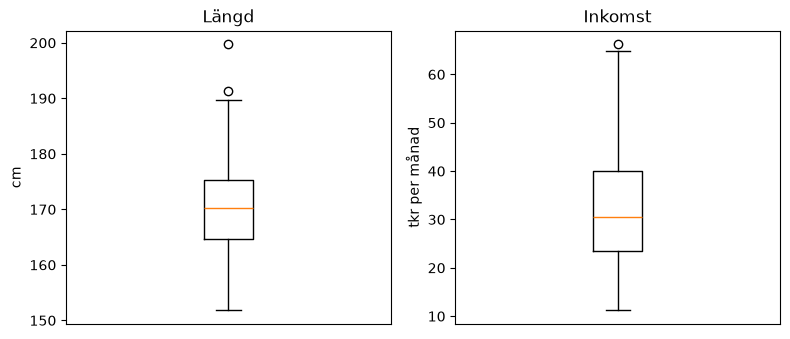

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].boxplot(sample["height"])
axes[0].set_title("Längd")
axes[0].set_ylabel("cm")
axes[1].boxplot(sample["income"])
axes[1].set_title("Inkomst")
axes[1].set_ylabel("tkr per månad")
for ax in axes:
    ax.set_xticks([])
plt.tight_layout()
plt.show()

I en högersned fördelning som inkomst ligger medianen närmare lådans nederkant, och det övre morrhåret är
längre än det nedre.

> **Prova själv:** Gör en frekvenstabell och ett stapeldiagram över `num_children` i `sample`. Vilket är typvärdet? Varför passar ett stapeldiagram bättre än ett histogram för den variabeln?

## 4. Analys av fördelningar

En **fördelning** beskriver hur värdena sprider sig. Två vanliga former:
- **Normalfördelning:** symmetrisk "klockform" (t.ex. längd).
- **Sned fördelning:** en lång svans åt ena hållet (t.ex. inkomst).

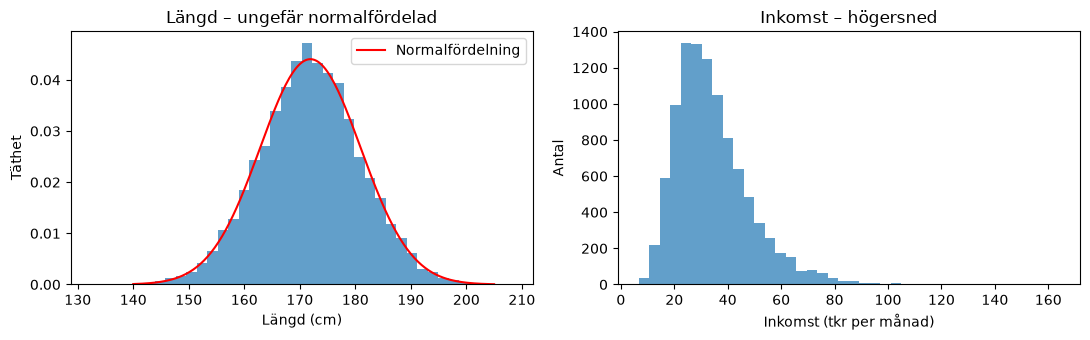

In [15]:
sigma = population["height"].std()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(population["height"], bins=40, density=True, alpha=0.7)
x = np.linspace(140, 205, 200)
axes[0].plot(x, stats.norm.pdf(x, mu, sigma), color="red", label="Normalfördelning")
axes[0].set_title("Längd – ungefär normalfördelad")
axes[0].set_xlabel("Längd (cm)")
axes[0].set_ylabel("Täthet")
axes[0].legend()
axes[1].hist(population["income"], bins=40, alpha=0.7)
axes[1].set_title("Inkomst – högersned")
axes[1].set_xlabel("Inkomst (tkr per månad)")
axes[1].set_ylabel("Antal")
plt.tight_layout()
plt.show()

I en normalfördelning ligger ungefär **68 %, 95 % och 99,7 %** av värdena inom 1, 2 och 3 standardavvikelser från medelvärdet:

In [16]:
for k in [1, 2, 3]:
    proportion = ((population["height"] - mu).abs() <= k * sigma).mean()
    print(f"Inom ±{k} standardavvikelser: {proportion:.1%}")

Inom ±1 standardavvikelser: 68.1%
Inom ±2 standardavvikelser: 95.6%
Inom ±3 standardavvikelser: 99.7%


> **Prova själv:** Gör samma beräkning för `income`. Stämmer 68–95–99,7-regeln lika bra för en sned fördelning?

## 5. Datakvalitet, felkällor och bias

| Felkälla | Vad det är | Exempel |
|---|---|---|
| **Urvalsfel** | Slumpmässig skillnad mellan stickprov och population | Minskar med större *n* |
| **Övertäckning** | Urvalsramen innehåller individer som inte tillhör populationen | Register med personer som flyttat |
| **Undertäckning** | Individer i populationen saknas i urvalsramen | Telefonenkät som bara når fasta telefoner, så unga saknas |
| **Bortfall** | Utvalda individer svarar inte | Låg svarsfrekvens i enkäter |
| **Mätfel** | Det registrerade värdet skiljer sig från det sanna | Ledande frågor, eller att man uppger en lägre vikt än man har |

**Bias** (systematiskt fel) uppstår när felet går åt ett bestämt håll, till exempel när bortfallet är
**systematiskt**. Ett snedvridet stickprov är inte **representativt** för populationen.

### Simulering: systematiskt bortfall

Anta att personer med hög inkomst är mindre benägna att svara på en enkät.

In [17]:
response_prob = np.clip(1.2 - population["income"] / 50, 0.05, 0.95)
responds = rng.random(N) < response_prob
respondents = population[responds]

print(f"Antal svarande: {len(respondents)}  (svarsfrekvens {responds.mean():.0%})")
print(f"Sann medelinkomst (alla):     {population['income'].mean():.1f} tkr")
print(f"Medelinkomst bland svarande:  {respondents['income'].mean():.1f} tkr")

Antal svarande: 5314  (svarsfrekvens 53%)
Sann medelinkomst (alla):     34.4 tkr
Medelinkomst bland svarande:  28.3 tkr


Jämför med ett litet men slumpmässigt stickprov utan bortfall:

In [18]:
srs_200 = population["income"].sample(200, random_state=2)
print(f"OSU med bara n = 200: {srs_200.mean():.1f} tkr")

OSU med bara n = 200: 35.6 tkr


**Slutsats:** Ett stort stickprov hjälper mot urvalsfel, men **inte mot bias**.
Tusentals svar med systematiskt bortfall kan ge en sämre skattning än 200 slumpmässigt valda.

> **Prova själv:** En tidning lägger ut en webbenkät om internetvanor och får 50 000 svar. Vilka felkällor finns, och åt vilket håll bör resultatet vara snedvridet?

## 6. Punktskattning och konfidensintervall

- **Punktskattning:** ett enda tal som skattar parametern, t.ex. x̄ som skattning av μ.
- **Konfidensintervall (KI):** ett intervall som anger osäkerheten i skattningen.

$$\text{KI} = \bar{x} \pm \underbrace{t^* \cdot \frac{s}{\sqrt{n}}}_{\text{felmarginal}}$$

- $s/\sqrt{n}$ kallas **medelfel** (standard error).
- $t^*$ hämtas från **t-fördelningen** med $n-1$ **frihetsgrader**.

**Förutsättningar:** stickprovet är slumpmässigt, och antingen är populationen ungefär normalfördelad eller så är
stickprovet tillräckligt stort för att centrala gränsvärdessatsen ska gälla (tumregel n ≥ 30).

In [19]:
n = len(height)
x_bar = height.mean()
s = height.std()
std_error = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)     # 95 %, dubbelsidigt
margin_of_error = t_crit * std_error

print(f"Punktskattning: x̄ = {x_bar:.2f} cm")
print(f"Felmarginal:    ±{margin_of_error:.2f}  (t* = {t_crit:.3f}, frihetsgrader = {n - 1})")
print(f"95 % KI:        [{x_bar - margin_of_error:.2f}, {x_bar + margin_of_error:.2f}]")
print(f"Sant μ:         {mu:.2f}")

Punktskattning: x̄ = 170.58 cm
Felmarginal:    ±1.65  (t* = 1.984, frihetsgrader = 99)
95 % KI:        [168.94, 172.23]
Sant μ:         171.91


Samma sak med en enda funktion:

In [20]:
stats.t.interval(0.95, df=n - 1, loc=x_bar, scale=std_error)

(np.float64(168.9355618491746), np.float64(172.2344381508253))

### Konfidensintervall för en andel

$$\hat{p} \pm z^* \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

**Förutsättning:** stickprovet är så stort att normalfördelningen passar. Tumregel: $n \cdot \hat{p}(1-\hat{p}) > 5$.
Här är det $100 \cdot 0{,}28 \cdot 0{,}72 \approx 20$.

In [21]:
std_error_p = np.sqrt(p_hat * (1 - p_hat) / n)
z_crit = stats.norm.ppf(0.975)
print(f"p̂ = {p_hat:.2f}, 95 % KI: [{p_hat - z_crit * std_error_p:.2f}, {p_hat + z_crit * std_error_p:.2f}]  (sant p = {p:.3f})")

p̂ = 0.28, 95 % KI: [0.19, 0.37]  (sant p = 0.355)


### Hur ska ett 95 % konfidensintervall tolkas?

Om vi upprepar undersökningen många gånger kommer **ungefär 95 % av intervallen att täcka det sanna μ**.
Det är alltså *metoden* som träffar rätt i 95 % av fallen.

> **Vanlig feltolkning:** "Det är 95 % sannolikhet att μ ligger i just det här intervallet." Men μ är ett fast tal,
> och ett färdigräknat intervall antingen täcker μ eller gör det inte. Vi vet bara inte vilket.

Vi drar 100 stickprov (n = 30) och ritar deras intervall:

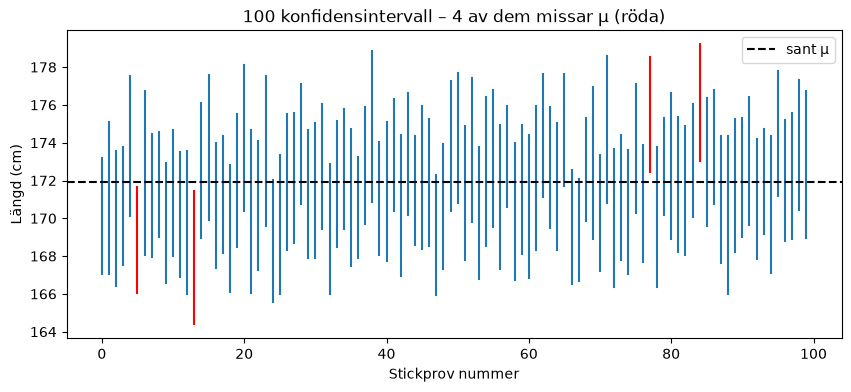

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
misses = 0
for i in range(100):
    one_sample = rng.choice(heights, 30, replace=False)
    m = one_sample.mean()
    h = stats.t.ppf(0.975, df=29) * one_sample.std(ddof=1) / np.sqrt(30)
    hit = m - h <= mu <= m + h
    misses += not hit
    ax.plot([i, i], [m - h, m + h], color="tab:blue" if hit else "red")
ax.axhline(mu, color="black", linestyle="--", label="sant μ")
ax.set_title(f"100 konfidensintervall – {misses} av dem missar μ (röda)")
ax.set_xlabel("Stickprov nummer")
ax.set_ylabel("Längd (cm)")
ax.legend()
plt.show()

### t-fördelningen och frihetsgrader

När σ är okänd och skattas med *s* används t-fördelningen i stället för normalfördelningen.
Med få frihetsgrader har den **tjockare svansar**, vilket ger bredare intervall. Med många frihetsgrader blir den nästan normalfördelad.

(I scipy heter argumentet för frihetsgrader `df`, *degrees of freedom*.)

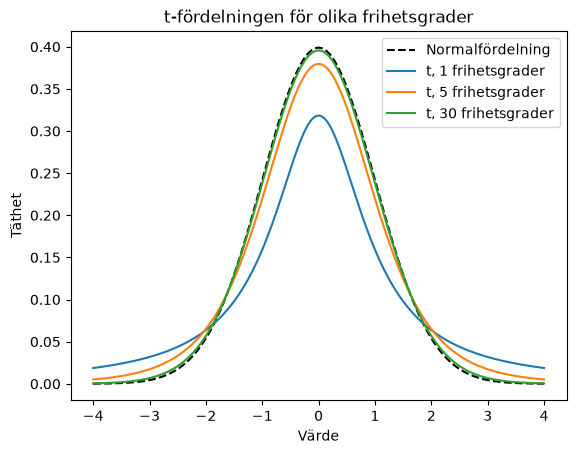

frihetsgrader =    5: t* = 2.571
frihetsgrader =   10: t* = 2.228
frihetsgrader =   30: t* = 2.042
frihetsgrader =  100: t* = 1.984
frihetsgrader = 1000: t* = 1.962
normalfördelning:     z* = 1.960


In [23]:
x = np.linspace(-4, 4, 300)
plt.plot(x, stats.norm.pdf(x), "k--", label="Normalfördelning")
for dof in [1, 5, 30]:
    plt.plot(x, stats.t.pdf(x, df=dof), label=f"t, {dof} frihetsgrader")
plt.xlabel("Värde")
plt.ylabel("Täthet")
plt.legend()
plt.title("t-fördelningen för olika frihetsgrader")
plt.show()

for dof in [5, 10, 30, 100, 1000]:
    print(f"frihetsgrader = {dof:>4}: t* = {stats.t.ppf(0.975, df=dof):.3f}")
print(f"normalfördelning:     z* = {stats.norm.ppf(0.975):.3f}")

> **Prova själv:** Räkna ut ett 99 % konfidensintervall för medellängden. Vilket tal ska ersätta `0.975`? Blir intervallet bredare eller smalare än 95 %-intervallet, och varför?

## 7. Hypotesprövning och statistisk signifikans

**Arbetsgång:**
1. Formulera **nollhypotes** $H_0$ (ingen skillnad/effekt) och **alternativhypotes** $H_1$.
2. Välj **signifikansnivå** α, oftast 0,05.
3. Beräkna en **testvariabel** från datan.
4. Beräkna **p-värdet**: sannolikheten att få ett resultat minst så extremt som det observerade, *om $H_0$ är sann*.
5. **Slutsats:** om p < α förkastas $H_0$, och skillnaden är **statistiskt säkerställd (signifikant)**.

> Att inte förkasta $H_0$ betyder **inte** att $H_0$ är bevisad, bara att vi saknar tillräckliga belägg mot den.
>
> p-värdet är **inte** sannolikheten att $H_0$ är sann. Det räknas ut *under antagandet* att $H_0$ är sann, och säger hur ovanlig vår data då vore.

### Exempel: t-test för ett medelvärde

Någon påstår att medellängden är 170 cm. $H_0: \mu = 170$ och $H_1: \mu \neq 170$.
Förutsättningarna är desamma som för konfidensintervallet i avsnitt 6.

In [24]:
mu_0 = 170
t_obs = (x_bar - mu_0) / std_error
p_value = 2 * stats.t.sf(abs(t_obs), df=n - 1)
print(f"Testvariabel t = {t_obs:.2f}")
print(f"p-värde        = {p_value:.4f}")

Testvariabel t = 0.70
p-värde        = 0.4832


Samma test med scipy:

In [25]:
stats.ttest_1samp(height, mu_0)

TtestResult(statistic=np.float64(0.7037347330041644), pvalue=np.float64(0.4832498909387963), df=np.int64(99))

In [26]:
alpha = 0.05
if p_value < alpha:
    print(f"p = {p_value:.4f} < {alpha}: förkasta H0. Medellängden skiljer sig signifikant från {mu_0} cm.")
else:
    print(f"p = {p_value:.4f} ≥ {alpha}: H0 kan inte förkastas.")

p = 0.4832 ≥ 0.05: H0 kan inte förkastas.

> **Fundera:** Vi vet att det sanna μ är ungefär 172 cm, alltså är $H_0$ egentligen falsk. Om testet ändå inte förkastade $H_0$ har vi gjort ett **typ II-fel**. Mer om det i avsnitt 9.

p-värdet är den skuggade arean i t-fördelningens svansar, bortom den observerade testvariabeln:

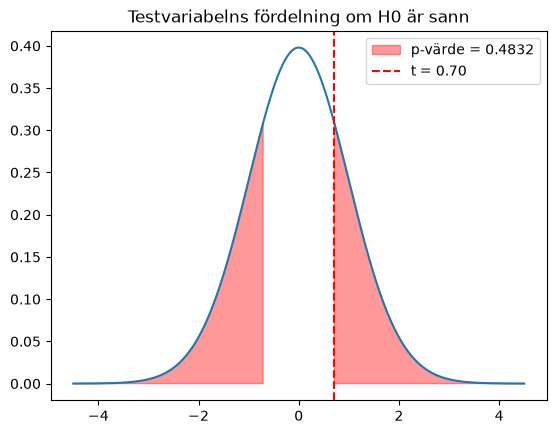

In [27]:
x = np.linspace(-4.5, 4.5, 400)
y = stats.t.pdf(x, df=n - 1)
plt.plot(x, y)
plt.fill_between(x, y, where=np.abs(x) >= abs(t_obs), color="red", alpha=0.4, label=f"p-värde = {p_value:.4f}")
plt.axvline(t_obs, color="red", linestyle="--", label=f"t = {t_obs:.2f}")
plt.legend()
plt.title("Testvariabelns fördelning om H0 är sann")
plt.show()

### Ensidig och dubbelsidig prövning

- **Dubbelsidig:** $H_1: \mu \neq 170$. Vi bryr oss om avvikelser åt båda hållen.
- **Ensidig:** $H_1: \mu > 170$. Vi bryr oss bara om en riktning.

Riktningen ska bestämmas **innan** man tittar på datan.

In [28]:
two_sided = stats.ttest_1samp(height, mu_0, alternative="two-sided")
one_sided_greater = stats.ttest_1samp(height, mu_0, alternative="greater")
one_sided_less = stats.ttest_1samp(height, mu_0, alternative="less")
print(f"Dubbelsidig (H1: μ ≠ 170): p = {two_sided.pvalue:.4f}")
print(f"Ensidig     (H1: μ > 170): p = {one_sided_greater.pvalue:.4f}")
print(f"Ensidig     (H1: μ < 170): p = {one_sided_less.pvalue:.4f}")

Dubbelsidig (H1: μ ≠ 170): p = 0.4832
Ensidig     (H1: μ > 170): p = 0.2416
Ensidig     (H1: μ < 170): p = 0.7584


Det ensidiga p-värdet är hälften av det dubbelsidiga **bara när avvikelsen går åt det håll som $H_1$ pekar ut**.
Här ligger x̄ över 170, så det gäller för $H_1: \mu > 170$. För $H_1: \mu < 170$ pekar datan åt fel håll,
och p-värdet blir i stället 1 − (halva det dubbelsidiga), alltså stort.

### t-test för skillnad mellan två medelvärden

Två undervisningsmetoder jämförs, med 40 elever per metod.
$H_0: \mu_A = \mu_B$ (ingen skillnad i medelpoäng) och $H_1: \mu_A \neq \mu_B$.

Titta alltid på datan innan du testar:

In [29]:
method_a = rng.normal(65, 12, 40).round()
method_b = rng.normal(74, 12, 40).round()
difference = method_a.mean() - method_b.mean()
print(f"Medelpoäng A: {method_a.mean():.1f}   B: {method_b.mean():.1f}   Skillnad (A − B): {difference:.1f}")

Medelpoäng A: 62.8   B: 70.1   Skillnad (A − B): -7.2


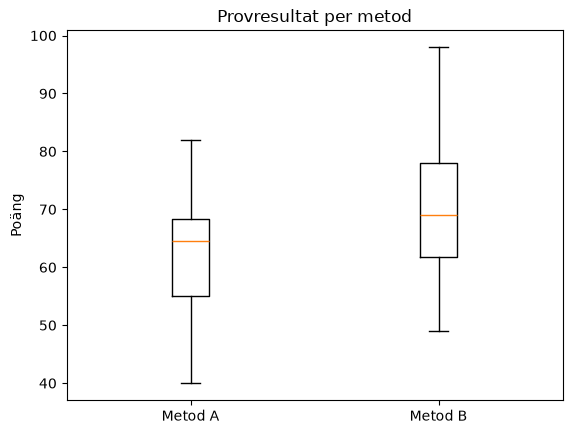

In [30]:
plt.boxplot([method_a, method_b])
plt.xticks([1, 2], ["Metod A", "Metod B"])
plt.ylabel("Poäng")
plt.title("Provresultat per metod")
plt.show()

In [31]:
res = stats.ttest_ind(method_a, method_b, equal_var=False)   # Welchs t-test
ci = res.confidence_interval(0.95)

print(f"t = {res.statistic:.2f},  p-värde = {res.pvalue:.4f}")
print(f"95 % KI för skillnaden (A − B): [{ci.low:.1f}, {ci.high:.1f}] poäng")
if res.pvalue < alpha:
    print("Slutsats: förkasta H0. Skillnaden i medelpoäng är statistiskt säkerställd.")
else:
    print("Slutsats: H0 kan inte förkastas. Vi saknar belägg för en skillnad i medelpoäng.")

t = -2.85,  p-värde = 0.0056
95 % KI för skillnaden (A − B): [-12.3, -2.2] poäng
Slutsats: förkasta H0. Skillnaden i medelpoäng är statistiskt säkerställd.


- **Tecknet på t** visar bara riktningen. scipy räknar A − B, så t blir negativt när metod A har lägre medelpoäng än B.
- **Konfidensintervallet** visar *hur stor* skillnaden kan vara, vilket p-värdet inte gör. Ett intervall som inte innehåller 0 säger samma sak som p < 0,05.
- **Förutsättningar:** två oberoende slumpmässiga stickprov, och ungefär normalfördelade värden eller tillräckligt stora grupper.

> **Prova själv:** Ändra gruppstorleken från 40 till 10 och kör om de tre cellerna. Blir skillnaden fortfarande signifikant? Vad händer med konfidensintervallets bredd?

## 8. Test för skillnad mellan två populationsandelar

Ett A/B-test: två versioner av en webbsida visas för 1 000 besökare var. Skiljer sig andelen som klickar?

$H_0: p_A = p_B$ och $H_1: p_A \neq p_B$

$$z = \frac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}$$

där $\hat{p}$ är den sammanvägda (poolade) andelen.

**Förutsättning:** stora stickprov, så att normalfördelningen passar (tumregel: $n\hat{p}(1-\hat{p}) > 5$ i båda grupperna).

In [32]:
clicks_a, n_a = 115, 1000
clicks_b, n_b = 150, 1000

p_a, p_b = clicks_a / n_a, clicks_b / n_b
p_pool = (clicks_a + clicks_b) / (n_a + n_b)
std_error_diff = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z = (p_b - p_a) / std_error_diff
p_value_prop = 2 * stats.norm.sf(abs(z))

print(f"Andel A: {p_a:.1%}   Andel B: {p_b:.1%}   Skillnad: {p_b - p_a:.1%}")
print(f"z = {z:.2f},  p-värde = {p_value_prop:.4f}")

if p_value_prop < alpha:
    print("Slutsats: förkasta H0. Andelen som klickar skiljer sig signifikant mellan versionerna.")
else:
    print("Slutsats: H0 kan inte förkastas.")

Andel A: 11.5%   Andel B: 15.0%   Skillnad: 3.5%
z = 2.31,  p-värde = 0.0210
Slutsats: förkasta H0. Andelen som klickar skiljer sig signifikant mellan versionerna.


**Kontroll med scipy.** Ett z-test för två andelar ger samma p-värde som ett chi-två-test (avsnitt 10) på tabellen
över klick och icke-klick, och $z^2 = \chi^2$:

In [33]:
table_ab = [[clicks_a, n_a - clicks_a],
             [clicks_b, n_b - clicks_b]]
res = stats.chi2_contingency(table_ab, correction=False)   # correction=False: utan kontinuitetskorrektion
print(f"χ² = {res.statistic:.2f}  (z² = {z**2:.2f}),  p-värde = {res.pvalue:.4f}")

χ² = 5.33  (z² = 5.33),  p-värde = 0.0210


Skillnaden är signifikant, men är den *viktig*? Om 3,5 procentenheter fler klick är mycket eller lite beror på
sammanhanget, och det kan testet inte avgöra.

> **Prova själv:** Anta samma andelar men bara 200 besökare per version (23 och 30 klick). Blir skillnaden signifikant? Vad säger det om stickprovsstorlekens betydelse?

## 9. Typ I- och typ II-fel

|  | $H_0$ är sann | $H_0$ är falsk |
|---|---|---|
| **Förkasta $H_0$** | ❌ **Typ I-fel** (falskt larm), sannolikhet α | ✅ Rätt |
| **Förkasta inte $H_0$** | ✅ Rätt | ❌ **Typ II-fel** (missad effekt), sannolikhet β |

**Styrka** = 1 − β = sannolikheten att upptäcka en effekt som faktiskt finns.

Vi simulerar 2 000 experiment för varje situation. Varje experiment jämför två grupper med ett t-test.
Värdena har standardavvikelsen 1, så en sann skillnad på 0,5 betyder **en halv standardavvikelse** (en medelstor effekt).

In [34]:
def share_rejected(true_difference, n_per_group, num_trials=2000, alpha=0.05):
    a = rng.normal(0, 1, (num_trials, n_per_group))
    b = rng.normal(true_difference, 1, (num_trials, n_per_group))
    p_values = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    return (p_values < alpha).mean()

print(f"Ingen verklig skillnad (H0 sann): förkastas i {share_rejected(0, 30):.1%} av fallen → typ I-fel ≈ α")
print()
for n_per_group in [10, 30, 100]:
    power = share_rejected(0.5, n_per_group)
    print(f"Sann skillnad 0,5 sd, n = {n_per_group:>3}: styrka {power:.0%}, typ II-fel {1 - power:.0%}")
print()
for true_difference in [0.2, 0.5, 0.8]:
    power = share_rejected(true_difference, 30)
    print(f"n = 30, sann skillnad {true_difference} sd: styrka {power:.0%}, typ II-fel {1 - power:.0%}")

Ingen verklig skillnad (H0 sann): förkastas i 5.5% av fallen → typ I-fel ≈ α

Sann skillnad 0,5 sd, n =  10: styrka 18%, typ II-fel 82%
Sann skillnad 0,5 sd, n =  30: styrka 48%, typ II-fel 52%
Sann skillnad 0,5 sd, n = 100: styrka 94%, typ II-fel 6%

n = 30, sann skillnad 0.2 sd: styrka 11%, typ II-fel 89%
n = 30, sann skillnad 0.5 sd: styrka 49%, typ II-fel 51%
n = 30, sann skillnad 0.8 sd: styrka 86%, typ II-fel 14%


- Typ I-fel styrs av α: med α = 0,05 får vi ett falskt larm i ungefär vart 20:e test där $H_0$ är sann.
- Typ II-fel minskar (styrkan ökar) när stickprovet blir större **och** när den verkliga effekten är större. Små effekter kräver stora stickprov.
- Ett lägre α ger färre typ I-fel men fler typ II-fel. Det är en avvägning.

> **Prova själv:** Kör `share_rejected(0.5, 30, alpha=0.01)`. Vad händer med styrkan när α sänks? Pröva dig sedan fram: ungefär hur många per grupp behövs för 80 % styrka när den sanna skillnaden är 0,5?

## 10. Sambandsanalys: korstabeller och chi-två-test

För att undersöka samband mellan **två kvalitativa variabler** används en **korstabell** och ett **chi-två-test (χ²)**.

Enkät: finns det ett samband mellan åldersgrupp och vilken kanal man helst handlar i?

In [35]:
num_responses = 300
age_group = rng.choice(["18–34", "35–54", "55+"], num_responses)
probabilities = {"18–34": [0.6, 0.3, 0.1], "35–54": [0.4, 0.4, 0.2], "55+": [0.25, 0.4, 0.35]}
channel = [rng.choice(["App", "Webb", "Butik"], p=probabilities[g]) for g in age_group]
survey = pd.DataFrame({"age_group": age_group, "channel": channel})

observed = pd.crosstab(survey["age_group"], survey["channel"])
pd.crosstab(survey["age_group"], survey["channel"], margins=True, margins_name="Totalt")

channel,App,Butik,Webb,Totalt
age_group,,,,
18–34,58,17,26,101
35–54,43,21,38,102
55+,21,34,42,97
Totalt,122,72,106,300


Radprocent gör det lättare att jämföra grupperna:

In [36]:
pd.crosstab(survey["age_group"], survey["channel"], normalize="index").round(2)

channel,App,Butik,Webb
age_group,,,
18–34,0.57,0.17,0.26
35–54,0.42,0.21,0.37
55+,0.22,0.35,0.43


### Observerade och förväntade frekvenser

$H_0$: inget samband (variablerna är oberoende). Om $H_0$ stämmer förväntar vi oss frekvenserna

$$E = \frac{\text{radsumma} \times \text{kolumnsumma}}{\text{totalt}}$$

Testvariabeln mäter hur mycket de observerade frekvenserna (O) avviker från de förväntade (E):

$$\chi^2 = \sum \frac{(O - E)^2}{E}$$

In [37]:
chi2, p_value_chi2, dof_chi2, expected = stats.chi2_contingency(observed)

print("Förväntade frekvenser om H0 är sann:")
display(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(1))
print(f"χ² = {chi2:.2f},  frihetsgrader = {dof_chi2},  p-värde = {p_value_chi2:.2g}")
if p_value_chi2 < alpha:
    print("Slutsats: förkasta H0. Det finns ett statistiskt säkerställt samband mellan åldersgrupp och kanal.")
else:
    print("Slutsats: H0 kan inte förkastas. Vi saknar belägg för ett samband.")

Förväntade frekvenser om H0 är sann:


channel,App,Butik,Webb
age_group,,,
18–34,41.1,24.2,35.7
35–54,41.5,24.5,36.0
55+,39.4,23.3,34.3


χ² = 27.73,  frihetsgrader = 4,  p-värde = 1.4e-05
Slutsats: förkasta H0. Det finns ett statistiskt säkerställt samband mellan åldersgrupp och kanal.


Frihetsgrader = (antal rader − 1) × (antal kolumner − 1).
Testet förutsätter att de förväntade frekvenserna är tillräckligt stora (tumregel: minst 5 i varje cell).

Testet säger bara *att* det finns ett samband, inte hur det ser ut eller hur starkt det är. Det ser man i
radprocenten: de yngsta föredrar appen, medan de äldsta oftare väljer webb eller butik.

> **Prova själv:** Jämför de observerade frekvenserna med de förväntade. I vilka celler är avvikelsen störst? Det är de cellerna som bidrar mest till χ².

## 11. Korrelationsanalys

Samband mellan **två kvantitativa variabler** visas med ett **spridningsdiagram** och mäts med
**Pearsons korrelationskoefficient r**:

- r = 1: perfekt positivt linjärt samband
- r = 0: inget *linjärt* samband
- r = −1: perfekt negativt linjärt samband

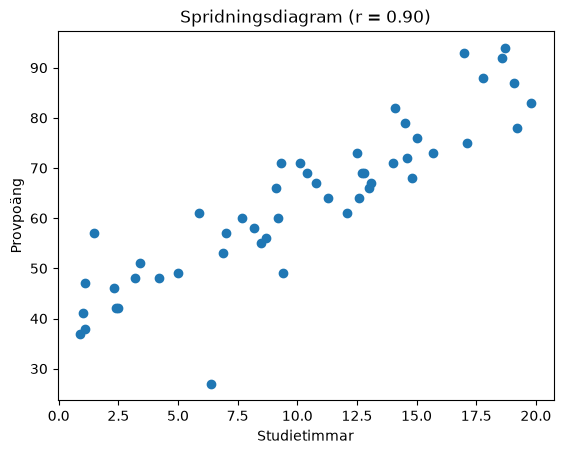

Pearsons r = 0.90,  p-värde = 9.2e-19


In [38]:
study_hours = rng.uniform(0, 20, 50).round(1)
exam_score = np.clip(40 + 2.5 * study_hours + rng.normal(0, 8, 50), 0, 100).round()

r, p_value_r = stats.pearsonr(study_hours, exam_score)

plt.scatter(study_hours, exam_score)
plt.xlabel("Studietimmar")
plt.ylabel("Provpoäng")
plt.title(f"Spridningsdiagram (r = {r:.2f})")
plt.show()
print(f"Pearsons r = {r:.2f},  p-värde = {p_value_r:.2g}")

p-värdet testar $H_0$: ingen linjär korrelation i populationen. Här är p långt under 0,05, så sambandet är
statistiskt säkerställt: fler studietimmar hänger ihop med högre provpoäng.

Hur olika värden på r ser ut. Den sista bilden visar ett tydligt samband där r ändå är nära 0, eftersom sambandet inte är linjärt:

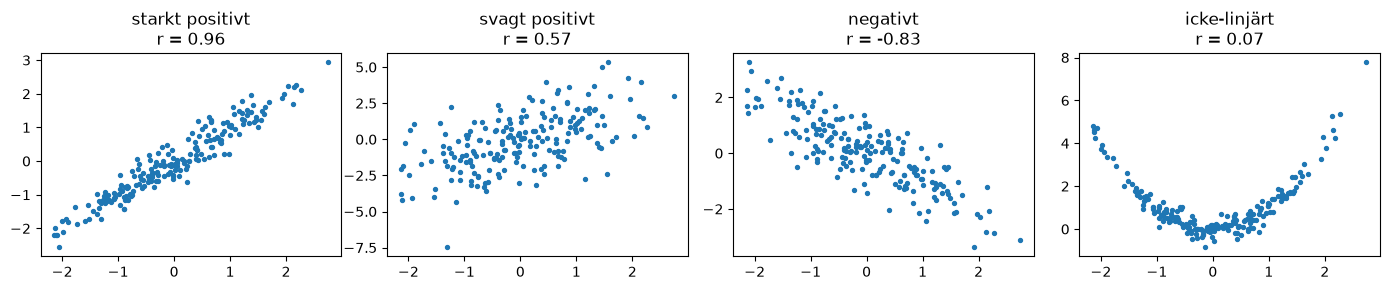

In [39]:
x = rng.normal(0, 1, 200)
examples = {
    "starkt positivt": x + rng.normal(0, 0.3, 200),
    "svagt positivt": x + rng.normal(0, 1.5, 200),
    "negativt": -x + rng.normal(0, 0.7, 200),
    "icke-linjärt": x**2 + rng.normal(0, 0.3, 200),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, y) in zip(axes, examples.items()):
    ax.scatter(x, y, s=8)
    ax.set_title(f"{name}\nr = {stats.pearsonr(x, y)[0]:.2f}")
plt.tight_layout()
plt.show()

> **Korrelation är inte kausalitet.** Glassförsäljning och drunkningsolyckor korrelerar, men båda beror på en tredje variabel: sommarvärmen.

> **Prova själv:** Hitta på ett eget exempel där två variabler korrelerar utan att den ena orsakar den andra. Vilken tredje variabel ligger bakom?

## 12. Enkel linjär regression

Regression beskriver sambandet med en **rät linje** som kan användas för att förutsäga *y* från *x*:

$$\hat{y} = a + b \cdot x$$

- **a (intercept):** förväntat y när x = 0.
- **b (lutning/regressionskoefficient):** hur mycket y förändras i genomsnitt när x ökar med 1.
- **R² (förklaringsgrad):** andelen av variationen i y som förklaras av x.

In [40]:
reg = stats.linregress(study_hours, exam_score)

print(f"Regressionsekvation:      provpoäng = {reg.intercept:.1f} + {reg.slope:.2f} · studietimmar")
print("Sanningen i simuleringen: provpoäng = 40.0 + 2.50 · studietimmar")
print(f"R² = {reg.rvalue**2:.2f}   (samma sak som r² = {r:.2f}² från avsnitt 11)")
print(f"p-värde för lutningen (H0: b = 0): {reg.pvalue:.2g}")

Regressionsekvation:      provpoäng = 38.2 + 2.48 · studietimmar
Sanningen i simuleringen: provpoäng = 40.0 + 2.50 · studietimmar
R² = 0.81   (samma sak som r² = 0.90² från avsnitt 11)
p-värde för lutningen (H0: b = 0): 9.2e-19


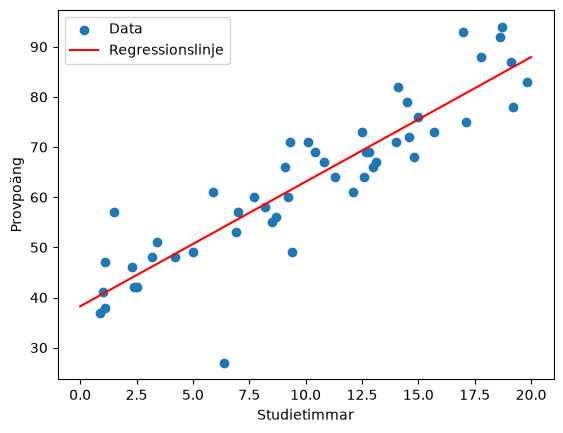

Prognos för 10 studietimmar: 63 poäng


In [41]:
x_line = np.linspace(0, 20, 100)
plt.scatter(study_hours, exam_score, label="Data")
plt.plot(x_line, reg.intercept + reg.slope * x_line, color="red", label="Regressionslinje")
plt.xlabel("Studietimmar")
plt.ylabel("Provpoäng")
plt.legend()
plt.show()

hours = 10
print(f"Prognos för {hours} studietimmar: {reg.intercept + reg.slope * hours:.0f} poäng")

**Tolkning:** varje extra studietimme är förknippad med i genomsnitt ungefär *b* poängs högre resultat.

**Jämför med sanningen:** datan skapades med a = 40 och b = 2,5. Skattningarna hamnar i närheten men inte exakt rätt,
av samma skäl som i avsnitt 1: vi har bara ett stickprov på 50 personer. Även regressionskoefficienter har alltså
urvalsfel, och därför redovisas de med medelfel och p-värden.

**R² och r:** i enkel linjär regression är R² lika med korrelationskoefficienten i kvadrat.

**Varning för extrapolering:** modellen bygger på data mellan 0 och 20 timmar. Att förutsäga resultatet för 60 timmar
skulle ge över 100 poäng, vilket är omöjligt.

> **Prova själv:** Vad blir prognosen för 0 och för 20 studietimmar? Skriv sedan ut `reg.stderr` (lutningens medelfel) och gör ett ungefärligt 95 % konfidensintervall för b med b ± 2 · medelfel. Täcker det det sanna värdet 2,5?

## 13. Samma analyser i R

Statistiska resultat presenteras ofta från R. Här är motsvarande kommandon:

| Analys | Python (scipy) | R |
|---|---|---|
| Medelvärde, standardavvikelse | `x.mean()`, `x.std()` | `mean(x)`, `sd(x)` |
| t-test, ett stickprov | `res = stats.ttest_1samp(x, 170)` | `t.test(x, mu = 170)` |
| Konfidensintervall, ett stickprov | `res.confidence_interval(0.95)` | ingår i utskriften från `t.test` |
| t-test, två grupper (Welch) | `stats.ttest_ind(a, b, equal_var=False)` | `t.test(a, b)` |
| Två andelar | manuellt z-test (avsnitt 8) | `prop.test(c(115, 150), c(1000, 1000))` |
| Chi-två-test | `stats.chi2_contingency(table)` | `chisq.test(table(age_group, channel))` |
| Pearsons korrelation | `stats.pearsonr(x, y)` | `cor.test(x, y)` |
| Linjär regression | `stats.linregress(x, y)` | `summary(lm(exam_score ~ study_hours))` |

Så här skriver R ut regressionen från avsnitt 12 (`summary(lm(exam_score ~ study_hours))`):

```
Coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)  38.2405     2.0288   18.85   <2e-16 ***
study_hours   2.4846     0.1754   14.16   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Multiple R-squared:  0.8069,	Adjusted R-squared:  0.8029
```

- **Estimate** = koefficienterna *a* och *b*. Jämför med regressionsekvationen i avsnitt 12.
- **Std. Error** = koefficientens medelfel, och **t value** = Estimate / Std. Error.
- **Pr(>|t|)** = p-värdet för testet av $H_0$: koefficienten är 0. `<2e-16` betyder "mindre än R kan skriva ut".
- **Stjärnorna** visar signifikansnivå enligt raden *Signif. codes*.
- **Multiple R-squared** = R². *Adjusted R-squared* är en variant som justerar för antalet förklarande variabler.

Obs: `prop.test` i R använder som standard en kontinuitetskorrektion, så p-värdet blir lite större än i vårt manuella z-test.
Detsamma gäller `chisq.test` och scipys `chi2_contingency` för tabeller med 2 × 2 celler.

## 14. Kritisk värdering av slutsatser

Frågor att ställa innan man litar på ett statistiskt resultat:

- **Hur togs stickprovet fram?** Var det slumpmässigt? Finns över- eller undertäckning?
- **Hur stort var bortfallet,** och kan det vara systematiskt (bias)?
- **Hur stor är osäkerheten?** Redovisas konfidensintervall eller felmarginal?
- **Är metodens förutsättningar uppfyllda?** Till exempel tillräckligt stora stickprov och oberoende observationer.
- **Signifikant betyder inte viktigt.** Med mycket stora stickprov blir även pyttesmå skillnader signifikanta. Titta på *hur stor* skillnaden är.
- **Icke-signifikant betyder inte "ingen skillnad".** Stickprovet kan ha varit för litet (typ II-fel).
- **Många tester ger falska larm.** Med 20 tester och α = 0,05 kan man förvänta sig ungefär ett signifikant resultat av ren slump (typ I-fel). Risken för *minst ett* falskt larm är 1 − 0,95²⁰ ≈ 64 %.
- **Korrelation är inte kausalitet.** Kan en tredje variabel förklara sambandet?
- **Extrapolera inte** en regressionsmodell utanför det intervall datan täcker.

Demonstration av "många tester": 20 t-tester där $H_0$ alltid är sann.

In [42]:
p_values = stats.ttest_ind(rng.normal(0, 1, (20, 30)), rng.normal(0, 1, (20, 30)), axis=1).pvalue
print(f"{(p_values < 0.05).sum()} av 20 tester blev 'signifikanta', trots att det inte finns någon verklig skillnad.")
print(np.round(np.sort(p_values), 3))

1 av 20 tester blev 'signifikanta', trots att det inte finns någon verklig skillnad.
[0.018 0.056 0.083 0.099 0.136 0.351 0.41  0.423 0.497 0.522 0.653 0.669
 0.741 0.821 0.833 0.872 0.899 0.922 0.923 0.993]


> **Prova själv:** Kör cellen ovan flera gånger. Hur ofta blir minst ett av de 20 testen "signifikant"? Stämmer det med 64 %?